In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import sqlite3
from pathlib import Path

print("Business Intelligence Dashboard")
print("All libraries imported successfully!")

Business Intelligence Dashboard
All libraries imported successfully!


In [2]:

data = {
    "Order_ID": list(range(1001, 1021)),
    "Product": [
        "Laptop", "Phone", "Headphones", "Monitor", "Keyboard",
        "Phone", "Laptop", "Mouse", "Monitor", "Headphones",
        "Keyboard", "Laptop", "Phone", "Mouse", "Monitor",
        "Headphones", "Laptop", "Keyboard", "Phone", "Mouse"
    ],
    "Category": [
        "Electronics", "Electronics", "Accessories", "Electronics",
        "Accessories", "Electronics", "Electronics", "Accessories",
        "Electronics", "Accessories", "Accessories", "Electronics",
        "Electronics", "Accessories", "Electronics", "Accessories",
        "Electronics", "Accessories", "Electronics", "Accessories"
    ],
    "Region": [
        "South", "North", "East", "West", "South",
        "East", "North", "West", "South", "East",
        "North", "West", "South", "East", "North",
        "West", "South", "East", "West", "North"
    ],
    "Quantity": [2, 3, 5, 2, 4, 2, 1, 6, 3, 4, 5, 2, 3, 4, 2, 5, 1, 3, 2, 6],
    "Unit_Price": [55000, 25000, 1500, 18000, 1200, 25000, 55000, 700, 18000, 1500, 1200, 55000, 25000, 700, 18000, 1500, 55000, 1200, 25000, 700],
    "Unit_Cost": [45000, 20000, 900, 14000, 700, 20000, 45000, 350, 14000, 900, 700, 45000, 20000, 350, 14000, 900, 45000, 700, 20000, 350]
}

df = pd.DataFrame(data)

df["Revenue"] = df["Quantity"] * df["Unit_Price"]
df["Profit"] = df["Quantity"] * (df["Unit_Price"] - df["Unit_Cost"])

df.head()


,Order_ID,Product,Category,Region,Quantity,Unit_Price,Unit_Cost,Revenue,Profit
0,1001,Laptop,Electronics,South,2,55000,45000,110000,20000
1,1002,Phone,Electronics,North,3,25000,20000,75000,15000
2,1003,Headphones,Accessories,East,5,1500,900,7500,3000
3,1004,Monitor,Electronics,West,2,18000,14000,36000,8000
4,1005,Keyboard,Accessories,South,4,1200,700,4800,2000


In [3]:

total_orders = df["Order_ID"].nunique()
total_revenue = df["Revenue"].sum()
total_profit = df["Profit"].sum()
total_units_sold = df["Quantity"].sum()
average_order_value = df["Revenue"].mean()

print("BUSINESS PERFORMANCE SUMMARY")
print("-----------------------------")
print("Total Orders:", total_orders)
print("Total Revenue: ₹", round(total_revenue, 2))
print("Total Profit: ₹", round(total_profit, 2))
print("Total Units Sold:", total_units_sold)
print("Average Order Value: ₹", round(average_order_value, 2))


BUSINESS PERFORMANCE SUMMARY
-----------------------------
Total Orders: 20
Total Revenue: ₹ 752600
Total Profit: ₹ 158000
Total Units Sold: 65
Average Order Value: ₹ 37630.0


In [4]:

product_sales = df.groupby("Product")["Revenue"].sum().sort_values(ascending=False)

print("PRODUCT-WISE REVENUE")
print(product_sales)

print("\nHighest Revenue Product:", product_sales.idxmax())
print("Highest Revenue Amount: ₹", round(product_sales.max(), 2))


PRODUCT-WISE REVENUE
Product
Laptop        330000
Phone         250000
Monitor       126000
Headphones     21000
Keyboard       14400
Mouse          11200
Name: Revenue, dtype: int64

Highest Revenue Product: Laptop
Highest Revenue Amount: ₹ 330000


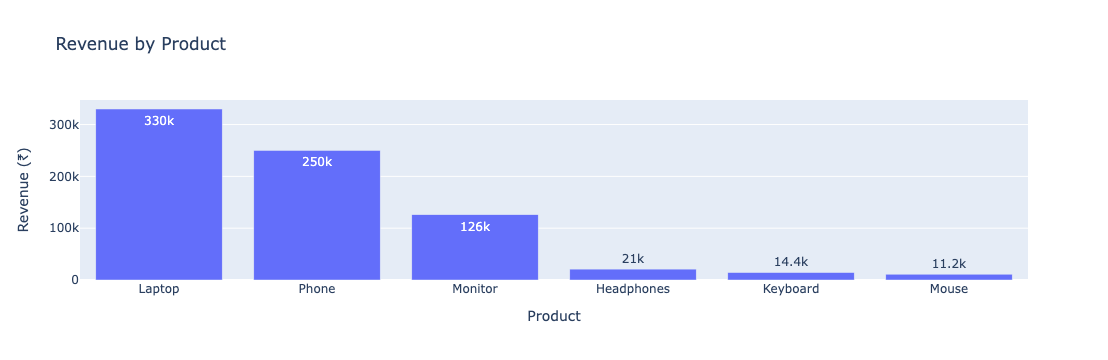

In [5]:

fig = px.bar(
    x=product_sales.index,
    y=product_sales.values,
    title="Revenue by Product",
    labels={
        "x": "Product",
        "y": "Revenue (₹)"
    },
    text_auto=True
)

fig.show()


In [6]:

region_sales = df.groupby("Region").agg(
    Total_Revenue=("Revenue", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Orders=("Order_ID", "nunique")
).sort_values("Total_Revenue", ascending=False)

print("REGION-WISE BUSINESS PERFORMANCE")
display(region_sales)

print("Best Performing Region:", region_sales["Total_Revenue"].idxmax())


REGION-WISE BUSINESS PERFORMANCE


,Total_Revenue,Total_Profit,Total_Orders
Region,,,
South,298800,59000,5
West,207700,43100,5
North,176200,37600,5
East,69900,18300,5


Best Performing Region: South


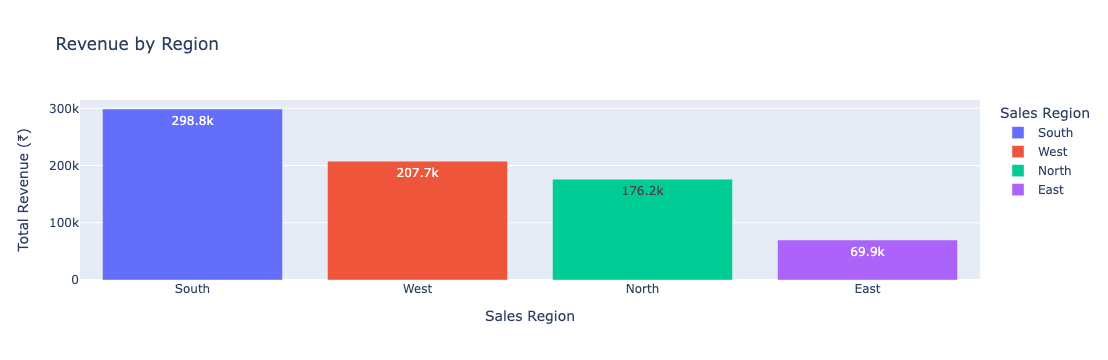

In [7]:

fig = px.bar(
    region_sales.reset_index(),
    x="Region",
    y="Total_Revenue",
    title="Revenue by Region",
    color="Region",
    text_auto=True,
    labels={
        "Region": "Sales Region",
        "Total_Revenue": "Total Revenue (₹)"
    }
)

fig.show()


In [8]:

product_profit = df.groupby("Product")["Profit"].sum().sort_values(ascending=False)

print("PROFIT BY PRODUCT")
display(product_profit.to_frame())

print("Most Profitable Product:", product_profit.idxmax())
print("Highest Total Profit: ₹", round(product_profit.max(), 2))


PROFIT BY PRODUCT


,Profit
Product,
Laptop,60000
Phone,50000
Monitor,28000
Headphones,8400
Keyboard,6000
Mouse,5600


Most Profitable Product: Laptop
Highest Total Profit: ₹ 60000


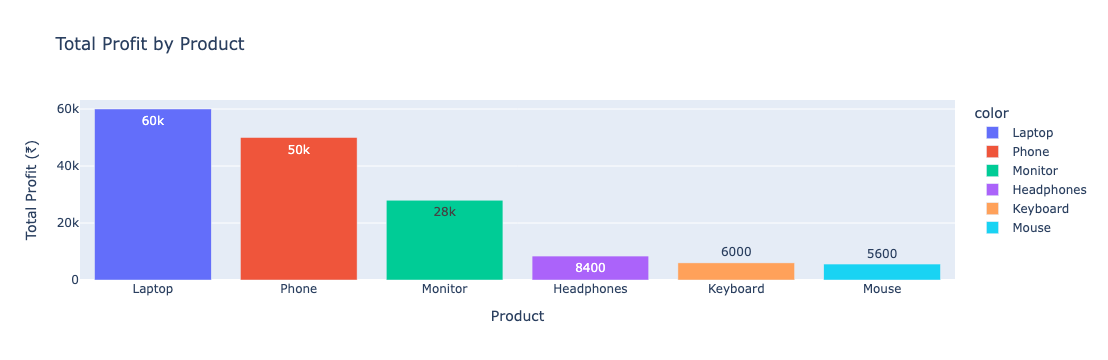

In [9]:

fig = px.bar(
    x=product_profit.index,
    y=product_profit.values,
    title="Total Profit by Product",
    labels={
        "x": "Product",
        "y": "Total Profit (₹)"
    },
    text_auto=True,
    color=product_profit.index
)

fig.show()


In [10]:

category_performance = df.groupby("Category").agg(
    Total_Revenue=("Revenue", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Units_Sold=("Quantity", "sum"),
    Total_Orders=("Order_ID", "nunique")
).sort_values("Total_Revenue", ascending=False)

print("CATEGORY-WISE BUSINESS PERFORMANCE")
display(category_performance)


CATEGORY-WISE BUSINESS PERFORMANCE


,Total_Revenue,Total_Profit,Total_Units_Sold,Total_Orders
Category,,,,
Electronics,706000,138000,23,11
Accessories,46600,20000,42,9


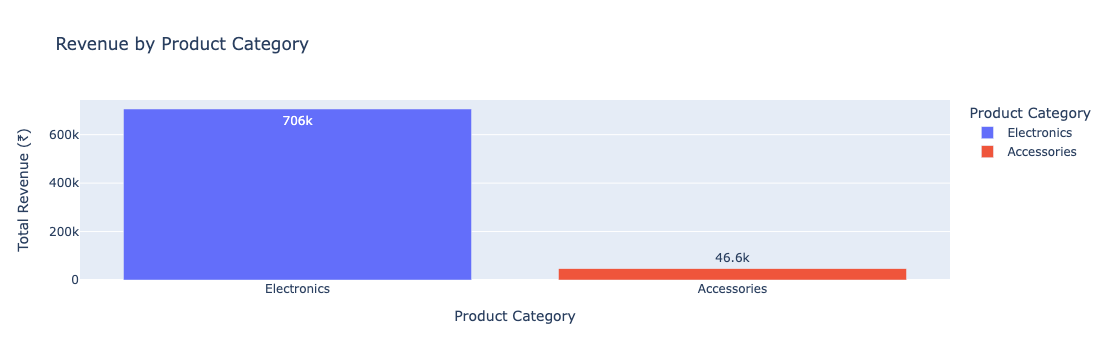

In [11]:

fig = px.bar(
    category_performance.reset_index(),
    x="Category",
    y="Total_Revenue",
    title="Revenue by Product Category",
    color="Category",
    text_auto=True,
    labels={
        "Category": "Product Category",
        "Total_Revenue": "Total Revenue (₹)"
    }
)

fig.show()


In [12]:

total_revenue = df["Revenue"].sum()
total_profit = df["Profit"].sum()

profit_margin = (total_profit / total_revenue) * 100

print("Total Revenue: ₹", round(total_revenue, 2))
print("Total Profit: ₹", round(total_profit, 2))
print("Profit Margin:", round(profit_margin, 2), "%")


Total Revenue: ₹ 752600
Total Profit: ₹ 158000
Profit Margin: 20.99 %


In [13]:

df["Order_Date"] = pd.to_datetime([
    "2026-01-05", "2026-01-12", "2026-01-18", "2026-01-25",
    "2026-02-03", "2026-02-09", "2026-02-15", "2026-02-21",
    "2026-03-02", "2026-03-08", "2026-03-14", "2026-03-20",
    "2026-04-04", "2026-04-10", "2026-04-16", "2026-04-22",
    "2026-05-05", "2026-05-11", "2026-05-17", "2026-05-23"
])

df[["Order_ID", "Order_Date", "Product", "Revenue", "Profit"]].head(10)


,Order_ID,Order_Date,Product,Revenue,Profit
0,1001,2026-01-05,Laptop,110000,20000
1,1002,2026-01-12,Phone,75000,15000
2,1003,2026-01-18,Headphones,7500,3000
3,1004,2026-01-25,Monitor,36000,8000
4,1005,2026-02-03,Keyboard,4800,2000
5,1006,2026-02-09,Phone,50000,10000
6,1007,2026-02-15,Laptop,55000,10000
7,1008,2026-02-21,Mouse,4200,2100
8,1009,2026-03-02,Monitor,54000,12000
9,1010,2026-03-08,Headphones,6000,2400


In [14]:

df["Month"] = df["Order_Date"].dt.to_period("M").astype(str)

monthly_sales = df.groupby("Month").agg(
    Total_Revenue=("Revenue", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Orders=("Order_ID", "nunique")
).reset_index()

print("MONTHLY BUSINESS PERFORMANCE")
display(monthly_sales)


MONTHLY BUSINESS PERFORMANCE


,Month,Total_Revenue,Total_Profit,Total_Orders
0,2026-01,228500,46000,4
1,2026-02,114000,24100,4
2,2026-03,176000,36900,4
3,2026-04,121300,27400,4
4,2026-05,112800,23600,4


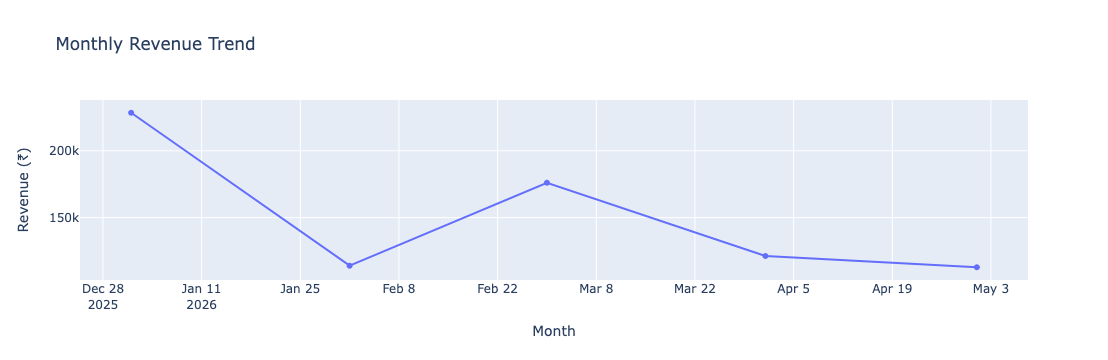

In [15]:

fig = px.line(
    monthly_sales,
    x="Month",
    y="Total_Revenue",
    title="Monthly Revenue Trend",
    markers=True,
    labels={
        "Month": "Month",
        "Total_Revenue": "Revenue (₹)"
    }
)

fig.show()


In [16]:

connection = sqlite3.connect("business_sales.db")

df.to_sql(
    "sales",
    connection,
    if_exists="replace",
    index=False
)

print("Sales data saved successfully!")
print("Database name: business_sales.db")
print("Table name: sales")


Sales data saved successfully!
Database name: business_sales.db
Table name: sales


In [17]:

query = """
SELECT
    Product,
    SUM(Revenue) AS Total_Revenue,
    SUM(Profit) AS Total_Profit
FROM sales
GROUP BY Product
ORDER BY Total_Revenue DESC;
"""

sql_result = pd.read_sql_query(query, connection)

print("PRODUCT PERFORMANCE FROM DATABASE")
display(sql_result)


PRODUCT PERFORMANCE FROM DATABASE


,Product,Total_Revenue,Total_Profit
0,Laptop,330000,60000
1,Phone,250000,50000
2,Monitor,126000,28000
3,Headphones,21000,8400
4,Keyboard,14400,6000
5,Mouse,11200,5600


In [18]:

summary = {
    "Total Orders": df["Order_ID"].nunique(),
    "Total Revenue (₹)": df["Revenue"].sum(),
    "Total Profit (₹)": df["Profit"].sum(),
    "Total Units Sold": df["Quantity"].sum(),
    "Average Order Value (₹)": df["Revenue"].mean(),
    "Profit Margin (%)": (df["Profit"].sum() / df["Revenue"].sum()) * 100,
    "Best Revenue Product": product_sales.idxmax(),
    "Best Performing Region": region_sales["Total_Revenue"].idxmax(),
    "Best Revenue Category": category_performance["Total_Revenue"].idxmax()
}

summary_df = pd.DataFrame(
    list(summary.items()),
    columns=["Business Metric", "Result"]
)

print("BUSINESS INTELLIGENCE SUMMARY DASHBOARD")
display(summary_df.round(2))


BUSINESS INTELLIGENCE SUMMARY DASHBOARD


,Business Metric,Result
0,Total Orders,20
1,Total Revenue (₹),752600
2,Total Profit (₹),158000
3,Total Units Sold,65
4,Average Order Value (₹),37630.0
5,Profit Margin (%),20.993888
6,Best Revenue Product,Laptop
7,Best Performing Region,South
8,Best Revenue Category,Electronics


In [19]:

df.to_csv("sales_data.csv", index=False)

print("Sales data saved successfully as sales_data.csv")


Sales data saved successfully as sales_data.csv


In [20]:

summary_df.to_csv("business_summary.csv", index=False)

print("Business summary saved successfully as business_summary.csv")


Business summary saved successfully as business_summary.csv


In [21]:

connection.close()

print("Database connection closed successfully!")
print("Business Intelligence Dashboard project saved!")


Database connection closed successfully!
Business Intelligence Dashboard project saved!


In [22]:

from pathlib import Path

print("Your current folder is:")
print(Path.cwd())

print("\nFiles in this folder:")
for file in Path.cwd().iterdir():
    print(file.name)


Your current folder is:
/Users/adithiramesh

Files in this folder:
Untitled7.ipynb
Music
saferoute_journey_report.csv
smart_expense_report.csv
saferoute.db
.zprofile.pysave
music.txt
Untitled5.ipynb
Untitled1.ipynb
sales_data.csv
SmartSpend — Personal Finance Manager.ipynb
.DS_Store
SafeRoute_Companion.ipynb
life_records.csv
SafeRoute_Companion
.thumbnails
business_sales.db
.CFUserTextEncoding
LifePatternDetective.ipynb
Untitled3.ipynb
smart_expenses.db
Untitled.ipynb
SmartSpend_AI
Untitled4.ipynb
.streamlit
.local
Untitled6.ipynb
Infertility Ad2.dra.zip
Pictures
.zprofile
business_summary.csv
SmartSpend_AI_Backup.ipynb
.zsh_history
Untitled2.ipynb
.ipython
Desktop
Library
.matplotlib
Infertility Ad2.dra
usiness_Intelligence_Dashboard.ipynb
Public
SafeRoute_Companion_Explanation.txt.rtf
.idlerc
.zen
Movies
app.py
UnrealEngine
SmartSpend_AI_Fresh.ipynb
Business_Intelligence_Dashboard
.Trash
.ipynb_checkpoints
.jupyter
.npm
Documents
.vscode
.swiftpm
Downloads
.cache
Smart_Expense_Analys